# Matched Filter Template Library

Load the default self-lensing matched-filter template library and inspect a representative sample of template shapes.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root(start=Path.cwd()):
    for path in (start, *start.parents):
        if (path / "pyproject.toml").exists() and (path / "searchlight").exists():
            return path
    raise RuntimeError("Could not find the astrosearchlight project root")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from searchlight.matched_filtering import (  # noqa: E402
    DEFAULT_TEMPLATE_LIBRARY_PATH,
    load_template_library,
)

template_library_path = PROJECT_ROOT / DEFAULT_TEMPLATE_LIBRARY_PATH
template_library_path

PosixPath('/home/anm1u24/Code/astrosearchlight/data/matched_filter_templates.npz')

If the default file is missing, generate it from the project root with:

```shell
uv sync --extra template-generation --all-groups
uv run python bin/generate_matched_filter_template_library.py
```

In [2]:
if not template_library_path.exists():
    raise FileNotFoundError(
        f"Template library not found at {template_library_path}. "
        "Generate it with bin/generate_matched_filter_template_library.py."
    )

library = load_template_library(template_library_path)
print(f"Loaded {len(library):,} templates from {template_library_path}")
print(f"Flux array shape: {library.flux.shape}")
print(f"Time range: {library.time[0]:.3f} to {library.time[-1]:.3f} days")
library.metadata

Loaded 442 templates from /home/anm1u24/Code/astrosearchlight/data/matched_filter_templates.npz
Flux array shape: (442, 737)
Time range: -30.654 to 30.680 days


{'cadence_minutes': 120.0,
 'half_window_days': 30.653792580971995,
 'window_scale': 1.2,
 'samples_per_parameter': 3,
 'include_distance': False,
 'distance_samples': 1,
 'include_self_lensing': True,
 'include_ellipsoidal_variations': True,
 'include_doppler_boosting': True,
 'lensing_method': None,
 'max_eccentricity': 0.999,
 'allow_rlof': False,
 'min_flux': 0.0,
 'skipped_invalid_flux': 0}

In [3]:
parameter_frame = None
if library.parameters is not None:
    parameter_frame = pd.DataFrame.from_records(library.parameters)
    display(parameter_frame.describe().T)
else:
    print("This template library does not include a parameter table.")

,count,mean,std,min,25%,50%,75%,max
a,442.0,83.561959,97.088352,1.000000e-01,4.472136e+00,4.472136,200.000000,2.000000e+02
i,442.0,1.570750,0.000041,1.570696e+00,1.570696e+00,1.570746,1.570796,1.570796e+00
Macc,442.0,18.296380,22.253853,5.000000e-01,5.000000e-01,5.000000,50.000000,5.000000e+01
Mcomp,442.0,16.311086,21.381826,5.000000e-01,5.000000e-01,5.000000,50.000000,5.000000e+01
e,442.0,0.291849,0.319321,0.000000e+00,0.000000e+00,0.413860,0.413860,9.990000e-01
periapsis_phase,442.0,3.141593,2.547590,0.000000e+00,0.000000e+00,3.141593,6.283185,6.283185e+00
d,442.0,1.000000,0.000000,1.000000e+00,1.000000e+00,1.000000,1.000000,1.000000e+00
Porb,442.0,105198.268684,185812.369353,1.557461e+00,3.454386e+02,1472.955339,143859.138169,1.033103e+06
b,442.0,4.568540,27.232663,1.159018e-14,1.639099e-12,0.096469,0.752558,3.182934e+02
tau_eff,442.0,6.365051,8.344859,1.557879e-02,2.649008e-01,2.678922,8.823614,2.554483e+01


In [4]:
max_plots = 12
sample_count = min(max_plots, len(library))
sample_indices = np.unique(
    np.linspace(0, len(library) - 1, sample_count, dtype=int)
)
sample_indices

array([  0,  40,  80, 120, 160, 200, 240, 280, 320, 360, 400, 441])

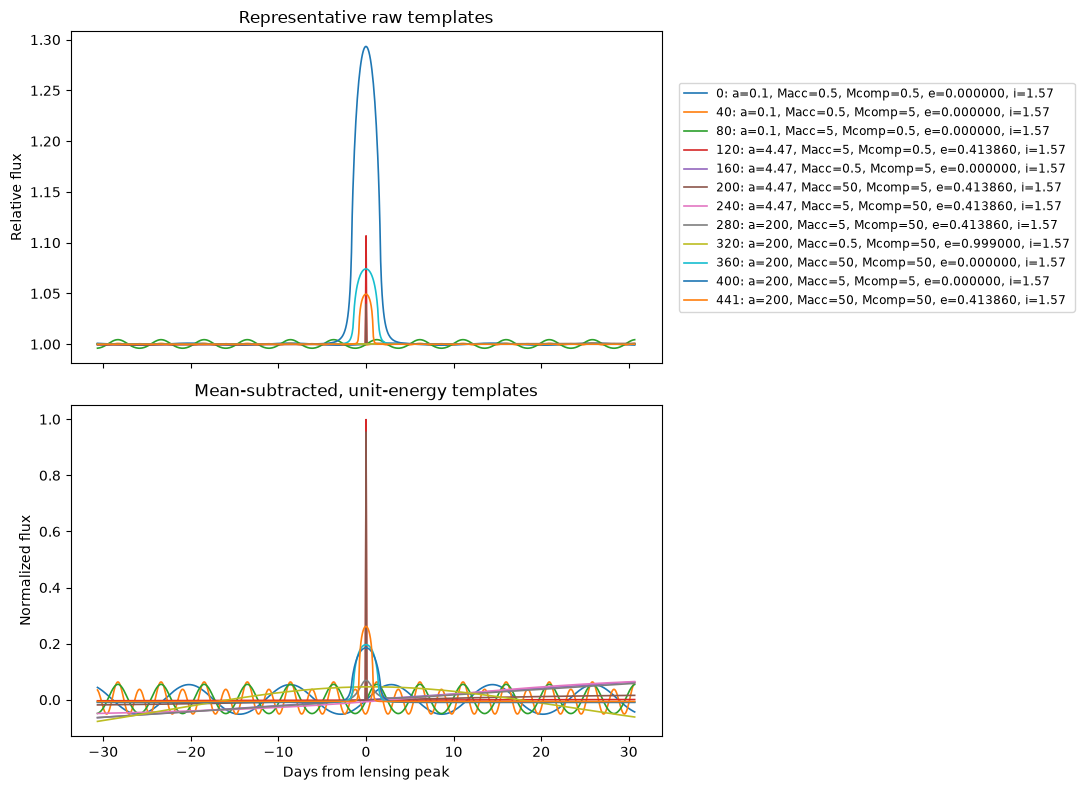

In [5]:
def normalise_template(flux):
    centered = flux - np.mean(flux)
    energy = np.sqrt(np.sum(centered ** 2))
    if energy == 0:
        return centered
    return centered / energy


def parameter_label(index):
    if parameter_frame is None:
        return f"template {index}"
    row = parameter_frame.iloc[index]
    fields = []
    for name in ("a", "Macc", "Mcomp", "e", "i"):
        if name in row:
            if name == "e":
                fields.append(f"{name}={row[name]:.6f}")
            else:
                fields.append(f"{name}={row[name]:.3g}")
    return f"{index}: " + ", ".join(fields)


fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

for index in sample_indices:
    flux = library.flux[index]
    axes[0].plot(library.time, flux, linewidth=1.2, label=parameter_label(index))
    axes[1].plot(library.time, normalise_template(flux), linewidth=1.2)

axes[0].set_title("Representative raw templates")
axes[0].set_ylabel("Relative flux")
axes[0].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize="small")

axes[1].set_title("Mean-subtracted, unit-energy templates")
axes[1].set_xlabel("Days from lensing peak")
axes[1].set_ylabel("Normalized flux")

fig.tight_layout()
plt.show()

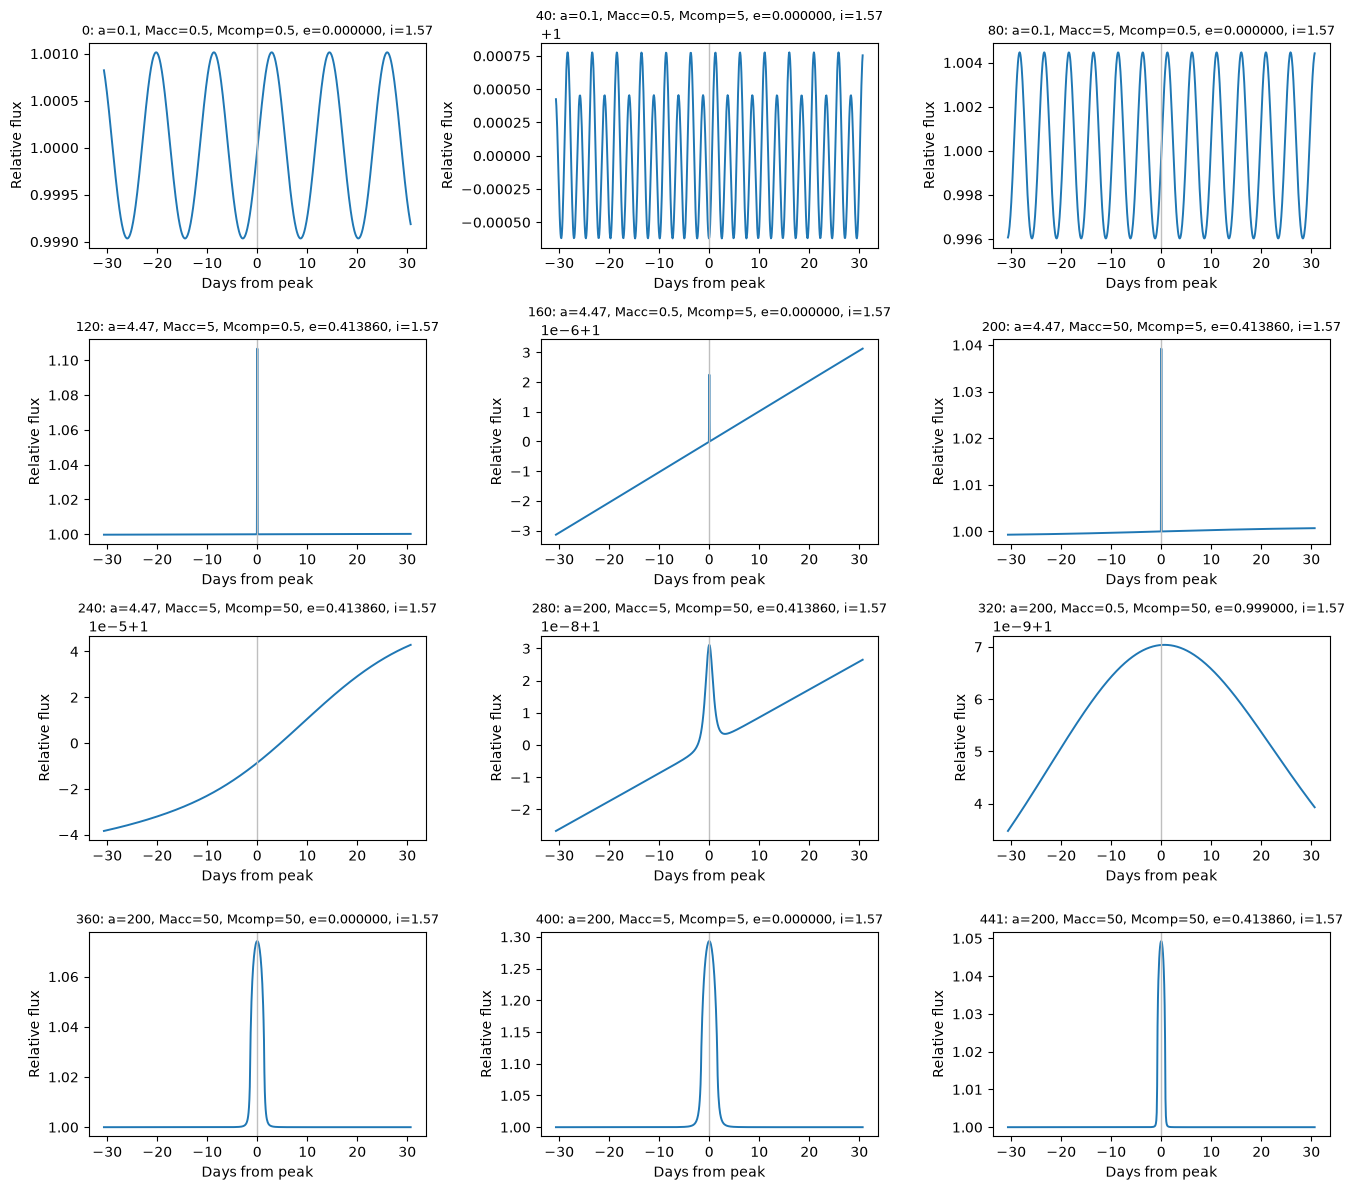

In [6]:
cols = min(3, len(sample_indices))
rows = int(np.ceil(len(sample_indices) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 3 * rows), squeeze=False)

for ax, index in zip(axes.ravel(), sample_indices):
    ax.plot(library.time, library.flux[index], color="tab:blue", linewidth=1.4)
    ax.axvline(0, color="0.75", linewidth=1)
    ax.set_title(parameter_label(index), fontsize=9)
    ax.set_xlabel("Days from peak")
    ax.set_ylabel("Relative flux")

for ax in axes.ravel()[len(sample_indices):]:
    ax.axis("off")

fig.tight_layout()
plt.show()